# Deforestation on a regular grid

Supports the article: Correia, L. F. C. S.; Rocha, T. V. S. M.; Bezerra, D. S.; Silva Junior, C. H. L.; Costa, S. S. *Expansão do desmatamento no cerrado maranhense entre os anos de 2001 – 2023*. Revista Tocantinense de Geografia, 15(35), 45–67, 2026. DOI: [10.70860/rtg.v15i35.19356](https://doi.org/10.70860/rtg.v15i35.19356)

Share of each 10 × 10 km cell deforested by 2000 and from 2001 to 2023 (**Figure 7** of the article). The grid removes the influence of the size of municipalities and microregions.

The grid is read from `dados/desmatamento/grade_cerrado_ma_prodes.zip`. Cell 44316 has an invalid value (497% deforested up to 2000) and is removed. The outlines of the selected Indigenous Lands (`dados/limites/tis_selecionadas.zip`) are an optional map layer: that file is not in the repository yet, and the map is drawn without it.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import seaborn as sns

In [2]:
import folium

In [3]:
df_grade = gpd.read_file("dados/desmatamento/grade_cerrado_ma_prodes.zip")
df_grade.head()

,top,left,bottom,target_per,right,id,2000_targe,d001_23,d2000,geometry
0,-5.237088,-47.939596,-5.320088,14.806995,-47.856596,40806,45.265392,14.806995,45.265392,"POLYGON ((-47.90064 -5.25347, -47.90064 -5.252..."
1,-5.320088,-47.939596,-5.403088,20.770221,-47.856596,40807,3.324870,20.770221,3.324870,"POLYGON ((-47.86840 -5.32758, -47.86804 -5.324..."
2,-5.237088,-47.856596,-5.320088,23.453269,-47.773596,41076,70.774158,23.453269,70.774158,"POLYGON ((-47.85660 -5.32009, -47.85660 -5.272..."
3,-5.320088,-47.856596,-5.403088,31.868517,-47.773596,41077,5.205989,31.868517,5.205989,"POLYGON ((-47.85660 -5.36082, -47.85660 -5.320..."
4,-5.237088,-47.773596,-5.320088,1.231868,-47.690596,41346,97.476698,1.231868,97.476698,"MULTIPOLYGON (((-47.77360 -5.32009, -47.77360 ..."


In [4]:
df_grade[df_grade["id"] == 44316]

,top,left,bottom,target_per,right,id,2000_targe,d001_23,d2000,geometry
291,-5.237088,-46.860596,-5.320088,0.0,-46.777596,44316,496.862745,0.0,496.862745,"MULTIPOLYGON (((-46.80325 -5.32009, -46.80283 ..."


In [5]:
#celula com valor errado 44316
df_grade = df_grade[df_grade["id"] != 44316]

In [6]:
df_grade

,top,left,bottom,target_per,right,id,2000_targe,d001_23,d2000,geometry
0,-5.237088,-47.939596,-5.320088,14.806995,-47.856596,40806,45.265392,14.806995,45.265392,"POLYGON ((-47.90064 -5.25347, -47.90064 -5.252..."
1,-5.320088,-47.939596,-5.403088,20.770221,-47.856596,40807,3.324870,20.770221,3.324870,"POLYGON ((-47.86840 -5.32758, -47.86804 -5.324..."
2,-5.237088,-47.856596,-5.320088,23.453269,-47.773596,41076,70.774158,23.453269,70.774158,"POLYGON ((-47.85660 -5.32009, -47.85660 -5.272..."
3,-5.320088,-47.856596,-5.403088,31.868517,-47.773596,41077,5.205989,31.868517,5.205989,"POLYGON ((-47.85660 -5.36082, -47.85660 -5.320..."
4,-5.237088,-47.773596,-5.320088,1.231868,-47.690596,41346,97.476698,1.231868,97.476698,"MULTIPOLYGON (((-47.77360 -5.32009, -47.77360 ..."
...,...,...,...,...,...,...,...,...,...,...
2801,-2.747088,-41.880596,-2.830088,0.344204,-41.797596,60486,1.461126,0.344204,1.461126,"POLYGON ((-41.88059 -2.83009, -41.88059 -2.747..."
2802,-2.830088,-41.880596,-2.913088,0.648848,-41.797596,60487,0.000000,0.648848,0.000000,"POLYGON ((-41.88059 -2.91309, -41.88059 -2.830..."
2803,-2.913088,-41.880596,-2.996088,11.179439,-41.797596,60488,12.337390,11.179439,12.337390,"POLYGON ((-41.88059 -2.99609, -41.88059 -2.913..."
2804,-2.996088,-41.880596,-3.079088,26.780587,-41.797596,60489,15.765769,26.780587,15.765769,"POLYGON ((-41.88059 -3.07665, -41.88059 -2.996..."


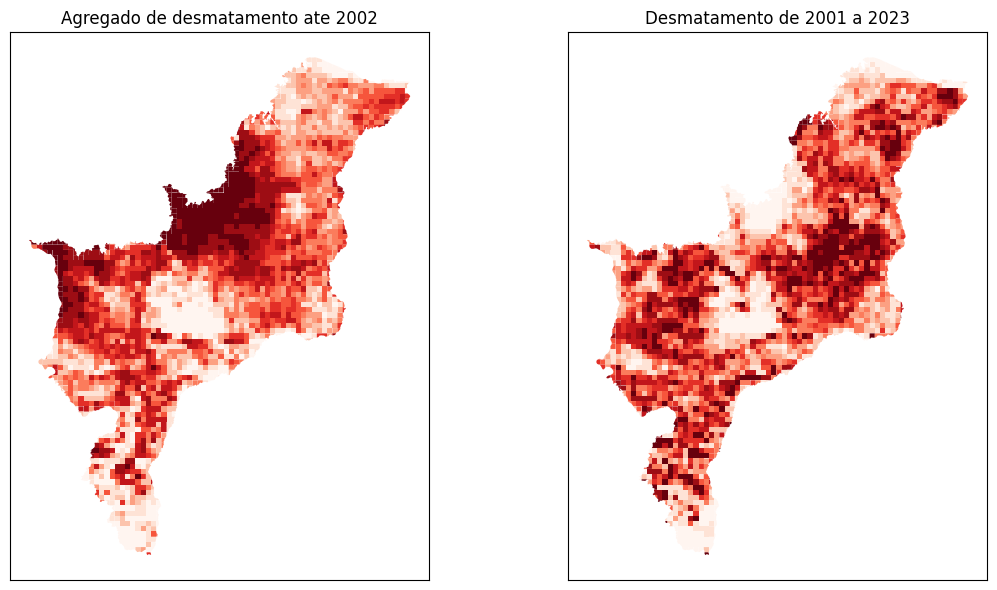

In [7]:
# Dividir a área de plotagem em dois subplots
fig, axs = plt.subplots(1, 2, figsize=(12, 6))


ax1 =  df_grade.plot(
    ax=axs[0],
    column="d2000",  # Data to plot
    scheme="quantiles",  # Classification scheme
    k=10,
    cmap="Reds",  # Color palette
    #legend=True,  # Add legend
    #legend_kwds={"fmt": "{:.0f}"},  # Remove decimals in legend
    figsize=(10,100),
    #edgecolor='black', linewidth=0.1,
)


axs[0].set_title('Agregado de desmatamento ate 2002')




ax2 = df_grade.plot(
    ax=axs[1],
    column="d001_23",  # Data to plot
    scheme="quantiles",  # Classification scheme
    k=10,
    cmap="Reds",  # Color palette
    #legend=True,  # Add legend
    #legend_kwds={"fmt": "{:.0f}"},  # Remove decimals in legend
    figsize=(10,100),
    #edgecolor='black', linewidth=0.1,
)

axs[1].set_title('Desmatamento de 2001 a 2023')



#axs[0].set_axis_off();
axs[0].set_xticks([])
axs[0].set_yticks([])

#axs[1].set_axis_off();
axs[1].set_xticks([])
axs[1].set_yticks([])

plt.tight_layout()  # Para ajustar os subplots para evitar sobreposição
plt.show()

In [8]:
df_grade["desmatamento_total"] = df_grade["d2000"] + df_grade["d001_23"]

In [9]:
mapa = folium.Map(location = [-4.4671541,-43.9278995,],
                      zoom_start = 7,
                      tiles = 'OpenStreetMap')

folium.Choropleth(geo_data = df_grade,
                  data= df_grade,
                  columns = ['id','d2000'],
                  key_on = 'feature.properties.id',
                  fill_color = 'RdYlGn_r',
                  nan_fill_color = 'white',
                  bins = 10,
                  highlight = True,
                  line_opacity=0,
                  legend_name = 'Porcentagem de Desmatamento').add_to(mapa)


mapa

In [10]:
mapa = folium.Map(location = [-4.4671541,-43.9278995,],
                      zoom_start = 7,
                      tiles = 'OpenStreetMap')

folium.Choropleth(geo_data = df_grade,
                  data= df_grade,
                  columns = ['id','desmatamento_total'],
                  key_on = 'feature.properties.id',
                  fill_color = 'RdYlGn_r',
                  nan_fill_color = 'white',
                  bins = 4,
                  highlight = True,
                  line_opacity=0,
                  legend_name = 'Porcentagem de Desmatamento').add_to(mapa)


mapa

In [11]:
import os

# Optional layer: outlines of the Indigenous Lands shown on the map below.
# The file is not in the repository yet; the map is drawn without it if it is missing.
path_ti = "dados/limites/tis_selecionadas.zip"
gdf_ti = gpd.read_file(path_ti) if os.path.exists(path_ti) else None
if gdf_ti is not None:
    gdf_ti.plot()
else:
    print(f"{path_ti} not found: the Indigenous Lands layer is skipped.")

dados/limites/tis_selecionadas.zip not found: the Indigenous Lands layer is skipped.


In [12]:
mapa = folium.Map(location = [-4.4671541,-43.9278995,],
                      zoom_start = 7,
                      tiles = 'OpenStreetMap')

folium.Choropleth(geo_data = df_grade,
                  data= df_grade,
                  columns = ['id','desmatamento_total'],
                  key_on = 'feature.properties.id',
                  fill_color = 'RdYlGn_r',
                  nan_fill_color = 'white',
                  bins = 4,
                  highlight = True,
                  line_opacity=0,
                  legend_name = 'Porcentagem de Desmatamento').add_to(mapa)

# Adicionar a camada do GeoDataFrame ao mapa
if gdf_ti is not None:
    folium.GeoJson(
        gdf_ti.to_json(),
        name='Camada GeoPandas',
        style_function=lambda x: {'weight': 1, 'color': 'black'}
    ).add_to(mapa)


mapa

In [13]:
import mapclassify

In [14]:

quantiles = mapclassify.Quantiles(df_grade['d001_23'], k=5)
df_grade['quantiles'] = quantiles.yb



In [15]:
natural_breaks = mapclassify.NaturalBreaks(df_grade['d001_23'], k=5)
df_grade['natural_breaks'] = natural_breaks.yb

In [16]:
mapa = folium.Map(location = [-4.4671541,-43.9278995,],
                      zoom_start = 7,
                      tiles = 'OpenStreetMap')

folium.Choropleth(geo_data = df_grade,
                  data= df_grade,
                  name='Equal Interval',
                  columns = ['id','natural_breaks'],
                  key_on = 'feature.properties.id',
                  fill_color = 'RdYlGn_r',
                  nan_fill_color = 'white',
                  #bins = 4,
                  highlight = True,
                  line_opacity=0,
                  legend_name = 'Porcentagem de Desmatamento').add_to(mapa)


mapa

In [17]:
import os
os.makedirs("temp", exist_ok=True)
df_grade.to_file("temp/desmatamento_grade.shp")

/tmp/ipykernel_248/1811654854.py:3: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  df_grade.to_file("temp/desmatamento_grade.shp")
